# 05 — Fotodetectores: detecção quadrática, banda, ruído e BER

Este notebook segue a aula (`docs/04-class/context.md`, "Fotodetectores") e o guia
`docs/fotodetectores.md`.

Regras usadas em todas as figuras (as mesmas dos notebooks anteriores):

- a física simulada vem **sempre** do pacote (`simcopy.kernels.photodetector`); o notebook só
  escreve as formas fechadas, que são a referência;
- forma fechada (linha) e simulação (pontos) juntas;
- as asserções numéricas ficam nos testes do pytest, escritos pelo grupo.

Fontes: Agrawal, *Sistemas de Comunicação por Fibra Óptica*, 4ª ed., seções 4.1, 4.4 e 4.6
(citado pelo número da equação), e o notebook do professor `4_EDFAsAndReceivers`, seção 2. O
texto separa **fato** (com a fonte) de **dedução**.

**Ainda não há bloco de fotodetector** (`components/rx`): a configuração depende das dúvidas
do guia. Aqui só o kernel.

## 0. Modelo

**[Fato: Agrawal, Eq. 4.1.1 e 4.1.3]** A fotocorrente é proporcional à potência óptica,
$I_p = R_dP_{in}$, com responsividade $R_d = \eta q/h\nu$.

**[Fato: notebook do professor, seção 2.0]** Para um campo nas duas polarizações,
$i_{pd}(t) = h_{pd}(t) * \left[R(|A_x|^2 + |A_y|^2) + n(t)\right]$, com $n$ a soma dos ruídos
de disparo e térmico e $h_{pd}$ a resposta do receptor.

**[Fato: Agrawal, Eq. 4.4.2–4.4.9]** O ruído de disparo tem densidade espectral bilateral
$qI$ e o térmico $2k_BT/R_L$; depois de um filtro de banda equivalente de ruído
$\Delta f = \int_0^\infty |H_T(f)|^2df$,

$$\sigma_s^2 = 2q(I_p + I_d)\Delta f,\qquad \sigma_T^2 = (4k_BT/R_L)F_n\Delta f$$

**[Dedução]** Numa corrente real amostrada a $f_s$, o ruído branco ocupa $[-f_s/2, f_s/2]$ e a
variância por amostra é a densidade bilateral vezes $f_s$: $qI f_s$ e $(2k_BT/R_L)f_s$. O kernel
faz isso. O código do professor usa a densidade **unilateral** vezes $f_s$, o que dobra os dois
ruídos (dúvida F1 do guia).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc

from simcopy.kernels.photodetector import (photocurrent, thermal_density, receiver_noise,
                                           lowpass_response, noise_bandwidth, apply_response)
from simcopy.core.grid import TimeGrid
from simcopy.core.units import Q_ELECTRON

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "legend.fontsize": 7.5})
C3 = ["tab:blue", "tab:orange", "tab:green"]
R = 1.0                                   # A/W, como o VPI (Responsivity = 1.0)
w = lambda p_dbm: 10 ** ((p_dbm - 30) / 10)

def tons(freqs, potencias, fases, pols, t):
    """Campo (2, N) com tons de potência e fase dadas, cada um numa polarização (0 = X, 1 = Y)."""
    E = np.zeros((2, t.size), dtype=complex)
    for fk, pk, phk, pol in zip(freqs, potencias, fases, pols):
        E[pol] += np.sqrt(pk) * np.exp(1j * (2 * np.pi * fk * t + phk))
    return E

def linha(corrente, freq, f_alvo):
    """Amplitude da componente da corrente em f_alvo (pico de um cosseno: 2|FFT|/N)."""
    k = np.argmin(np.abs(freq - f_alvo))
    return (1 if f_alvo == 0 else 2) * np.abs(np.fft.fft(corrente)[k]) / corrente.size

## 1. Detecção quadrática: batimentos

**[Dedução, da Eq. 4.1.1]** O detector responde a $|A|^2$, não ao campo. Dois tons na mesma
polarização, de potências $P_1$ e $P_2$ separados de Δf, dão
$I(t) = R[P_1 + P_2 + 2\sqrt{P_1P_2}\cos(2\pi\Delta f\,t + \Delta\phi)]$: aparece uma componente
elétrica em Δf, o batimento. Em polarizações ortogonais os campos não se somam, e a corrente
é só $R(P_1 + P_2)$. Com três tons igualmente espaçados, os dois batimentos na mesma
frequência se somam com fase, e podem se cancelar (exemplo do professor, seção 2.1).

2 tons, mesma pol. (1 e 0,5 mW, ±2,5 GHz): DC 1.5000 mA | 5 GHz 1.4142 | 10 GHz 2.47e-16 | 20 GHz 0.0000
2 tons, pol. ortogonais: DC 1.5000 mA | 5 GHz 0.0000 | 10 GHz 2.59e-17 | 20 GHz 0.0000
3 tons, fase π/2 nos laterais: DC 11.0000 mA | 5 GHz 0.0000 | 10 GHz 1.40e-12 | 20 GHz 6.0000


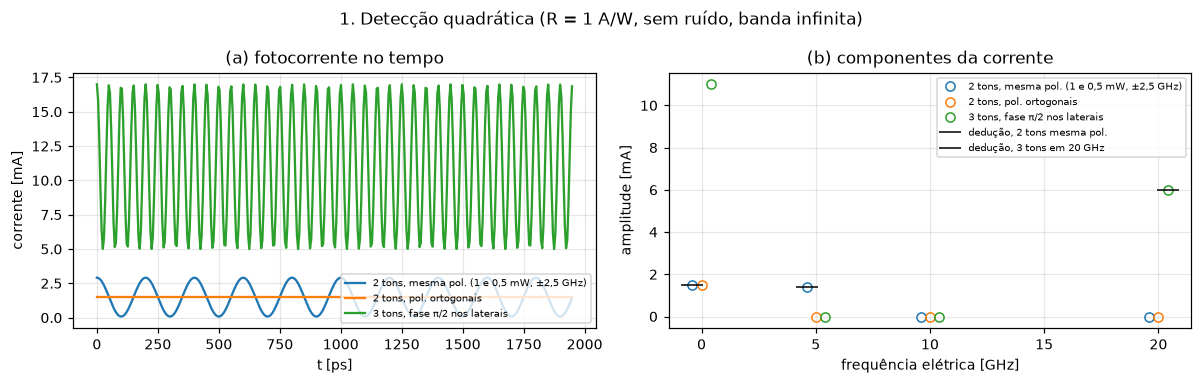

In [2]:
FS1, N1 = 204.8e9, 2 ** 14               # bins de 12,5 MHz: os tons caem em bins exatos
g1 = TimeGrid(FS1, N1)
t1, f1 = g1.time, g1.freq
casos = {
    "2 tons, mesma pol. (1 e 0,5 mW, ±2,5 GHz)": tons([-2.5e9, 2.5e9], [1e-3, 0.5e-3], [0, 0], [0, 0], t1),
    "2 tons, pol. ortogonais": tons([-2.5e9, 2.5e9], [1e-3, 0.5e-3], [0, 0], [0, 1], t1),
    "3 tons, fase π/2 nos laterais": tons([-10e9, 0, 10e9], [3e-3, 5e-3, 3e-3],
                                         [np.pi / 2, 0, np.pi / 2], [0, 0, 0], t1),
}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for i, (nome, E) in enumerate(casos.items()):
    I = photocurrent(E, R)
    ax[0].plot(t1[:400] * 1e12, I[:400] * 1e3, color=C3[i], label=nome)
    fl = np.array([0, 5e9, 10e9, 20e9])
    ax[1].plot(fl / 1e9 + (i - 1) * 0.4, [linha(I, f1, x) * 1e3 for x in fl], "o", mfc="none",
               color=C3[i], label=nome)
P1, P2 = 1e-3, 0.5e-3
ax[1].plot([0 - 0.4, 5 - 0.4], [R * (P1 + P2) * 1e3, 2 * R * np.sqrt(P1 * P2) * 1e3], "k_", ms=14,
           label="dedução, 2 tons mesma pol.")
# 3 tons: batimentos em 10 GHz se cancelam: 2√(P1P2)[cos(.. + π/2) + cos(.. - π/2)] = 0
ax[1].plot([20 + 0.4], [2 * R * 3e-3 * 1e3], "k_", ms=14, label="dedução, 3 tons em 20 GHz")
ax[0].set(xlabel="t [ps]", ylabel="corrente [mA]", title="(a) fotocorrente no tempo")
ax[1].set(xlabel="frequência elétrica [GHz]", ylabel="amplitude [mA]",
          title="(b) componentes da corrente")
ax[0].legend(fontsize=6.5, loc="lower right"); ax[1].legend(fontsize=6.5)
fig.suptitle("1. Detecção quadrática (R = 1 A/W, sem ruído, banda infinita)")
fig.tight_layout()
for nome, E in casos.items():
    I = photocurrent(E, R)
    print(f"{nome}: DC {linha(I, f1, 0)*1e3:.4f} mA | 5 GHz {linha(I, f1, 5e9)*1e3:.4f} | "
          f"10 GHz {linha(I, f1, 10e9)*1e3:.2e} | 20 GHz {linha(I, f1, 20e9)*1e3:.4f}")

**Leitura.** (Números na saída da célula.)
- Na mesma polarização, os dois tons dão DC de 1,5 mA e batimento de $2\sqrt{P_1P_2}R$ = 1,41 mA
  em 5 GHz. Em polarizações ortogonais só sobra o DC: o detector soma potências por
  polarização. Isso importa para a ASE (notebook 04) e para o receptor coerente, que precisa
  do oscilador local na mesma polarização do sinal.
- Com três tons espaçados de 10 GHz e fase π/2 nos laterais, os dois batimentos em 10 GHz
  (central com cada lateral) se cancelam, e o de 20 GHz (lateral com lateral) fica com
  $2R\cdot3$ mW = 6 mA. É o caso do professor: a corrente depende das fases relativas dos
  tons, não só das potências.

## 2. Banda do receptor

**[Fato: Agrawal, Eq. 4.1.6–4.1.9]** Um circuito RC responde a um degrau com
$1 - e^{-t/RC}$; o tempo de subida (10–90 %) é $T_r = \ln 9\,RC \approx 2{,}2\,\tau_{RC}$, e a banda
$\Delta f = 1/(2\pi\tau_{RC})$. **[Dedução]** Então $T_r = \ln 9/(2\pi\Delta f) \approx 0{,}35/\Delta f$.

**[Fato: VPI e configuração]** O receptor do VPI usa filtro de Bessel de ordem 4 com
1,15 × taxa de símbolos; o `PhotodiodeConfig` aceita Bessel ou Butterworth. **[Fato:
arquitetura, C-21]** Bessel pela fase linear. O professor usa um elíptico (P-15 na
arquitetura: ordem dependente de $f_s$ e fase não linear).

O kernel aplica a resposta $H(f)$ do filtro analógico na FFT, e calcula a banda equivalente de
ruído $\Delta f$ da Eq. 4.4.4 a partir da própria resposta.

RC (Butterworth ordem 1): tempo de subida 35.0 ps | Δf de ruído = 15.208 GHz (1.521·B) | sobressinal 0.9 %
Butterworth ordem 4: tempo de subida 37.5 ps | Δf de ruído = 10.262 GHz (1.026·B) | sobressinal 10.8 %
Bessel ordem 4: tempo de subida 35.0 ps | Δf de ruído = 10.464 GHz (1.046·B) | sobressinal 0.8 %
Dedução para o RC: T_r = ln9/(2πΔf) = 35.0 ps


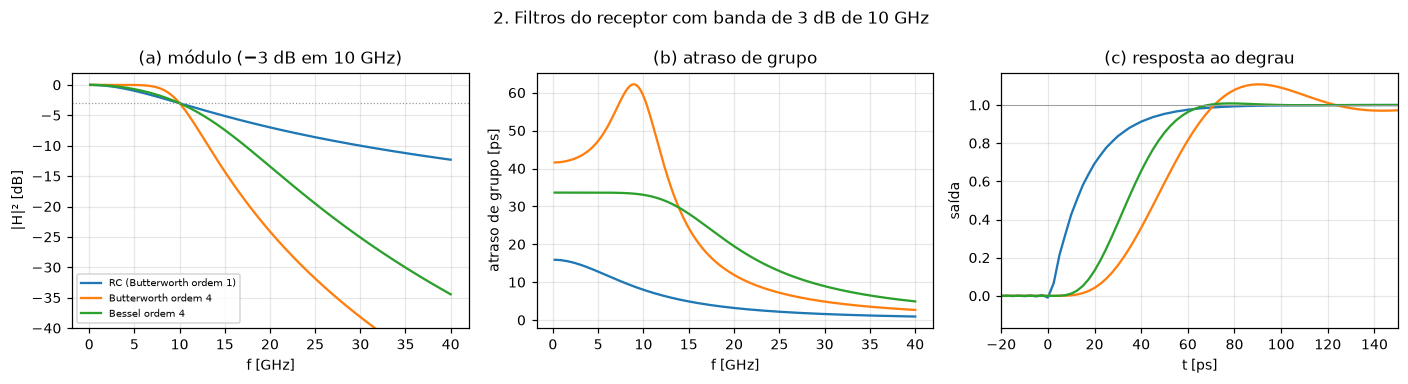

In [3]:
FS2, N2 = 400e9, 2 ** 16
g2 = TimeGrid(FS2, N2)
t2, f2 = g2.time, g2.freq
B = 10e9
filtros = {"RC (Butterworth ordem 1)": ("butterworth", 1), "Butterworth ordem 4": ("butterworth", 4),
           "Bessel ordem 4": ("bessel", 4)}
degrau = (t2 >= 1e-9).astype(float)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
fpos = np.linspace(0.1e9, 40e9, 400)
for i, (nome, (kind, ordem)) in enumerate(filtros.items()):
    Hp = lowpass_response(fpos, B, kind, ordem)
    ax[0].plot(fpos / 1e9, 20 * np.log10(np.abs(Hp)), color=C3[i], label=nome)
    fase = np.unwrap(np.angle(Hp))
    ax[1].plot(fpos[1:] / 1e9, -np.diff(fase) / np.diff(2 * np.pi * fpos) * 1e12, color=C3[i])
    y = apply_response(degrau, lowpass_response(f2, B, kind, ordem))
    ax[2].plot((t2 - 1e-9) * 1e12, y, color=C3[i])
    i0 = np.argmax(degrau > 0)                     # mede a subida a partir do degrau (a FFT é circular)
    i10, i90 = i0 + np.argmax(y[i0:] > 0.1), i0 + np.argmax(y[i0:] > 0.9)
    df = noise_bandwidth(lowpass_response(f2, B, kind, ordem), f2)
    print(f"{nome}: tempo de subida {(t2[i90]-t2[i10])*1e12:.1f} ps | Δf de ruído = {df/1e9:.3f} GHz "
          f"({df/B:.3f}·B) | sobressinal {100*(y.max()-1):.1f} %")
ax[0].axhline(-3, color="0.6", ls=":", lw=0.8)
ax[0].set(ylim=(-40, 2), xlabel="f [GHz]", ylabel="|H|² [dB]", title="(a) módulo (−3 dB em 10 GHz)")
ax[1].set(xlabel="f [GHz]", ylabel="atraso de grupo [ps]", title="(b) atraso de grupo")
ax[2].axhline(1, color="0.6", lw=0.6)
ax[2].set(xlim=(-20, 150), xlabel="t [ps]", ylabel="saída", title="(c) resposta ao degrau")
ax[0].legend(fontsize=6.5)
fig.suptitle("2. Filtros do receptor com banda de 3 dB de 10 GHz")
fig.tight_layout()
print(f"Dedução para o RC: T_r = ln9/(2πΔf) = {np.log(9)/(2*np.pi*B)*1e12:.1f} ps")

**Leitura.** (Números na saída da célula.)
- O RC tem o tempo de subida da dedução das Eq. 4.1.7–4.1.9 ($\ln 9/(2\pi\cdot10$ GHz) = 35 ps)
  e a maior banda de ruído: deixa passar muito ruído acima de B. **[Dedução]** Com banda infinita
  ela seria $\pi/2$ = 1,57 vezes a de 3 dB; aqui sai 1,52 porque a grade só vai até
  $f_s/2$ = 200 GHz e corta a cauda lenta do RC.
- O Bessel tem atraso de grupo quase constante (b): todas as frequências do sinal atrasam igual
  e o pulso não deforma; quase não tem sobressinal (c). O Butterworth de mesma ordem corta mais
  rápido, mas tem atraso variável e sobressinal, o que gera interferência entre símbolos.
- A banda equivalente de ruído dos filtros de ordem 4 fica perto da banda de 3 dB (~1,05·B):
  é ela, e não a de 3 dB, que entra nas Eq. 4.4.5 e 4.4.9.

## 3. Ruído de disparo e ruído térmico

**[Fato: Agrawal, Eq. 4.4.10–4.4.13]** As duas variâncias se somam,
$\sigma^2 = 2q(I_p + I_d)\Delta f + (4k_BT/R_L)F_n\Delta f$, e
$\mathrm{SNR} = R_d^2P_{in}^2/\sigma^2$. No limite térmico a SNR cresce com $P_{in}^2$; no
limite de disparo, com $P_{in}$. **[Dedução]** As duas variâncias se igualam em
$P_\times = i_n^2/(2qR_d)$, com $i_n$ a densidade de corrente do ruído térmico (exercício 1 do
professor).

**[Fato: VPI]** `ThermalNoise = 10e-12` A/√Hz. **[Dedução]** Com $4k_BT/R_L$, 300 K e 50 Ω
(professor), $i_n$ = 18,2 pA/√Hz.

Δf = 10.464 GHz | P_× = -5.06 dBm | disparo medido/Eq. 4.4.5: [0.9995 0.9988 0.9926 0.9759 0.9575 1.0072] | térmico medido/Eq. 4.4.9: [0.9966 1.01   0.9957 1.0382 0.9701 1.0239]
4k_BT/R_L (300 K, 50 Ω): 18.2 pA/√Hz


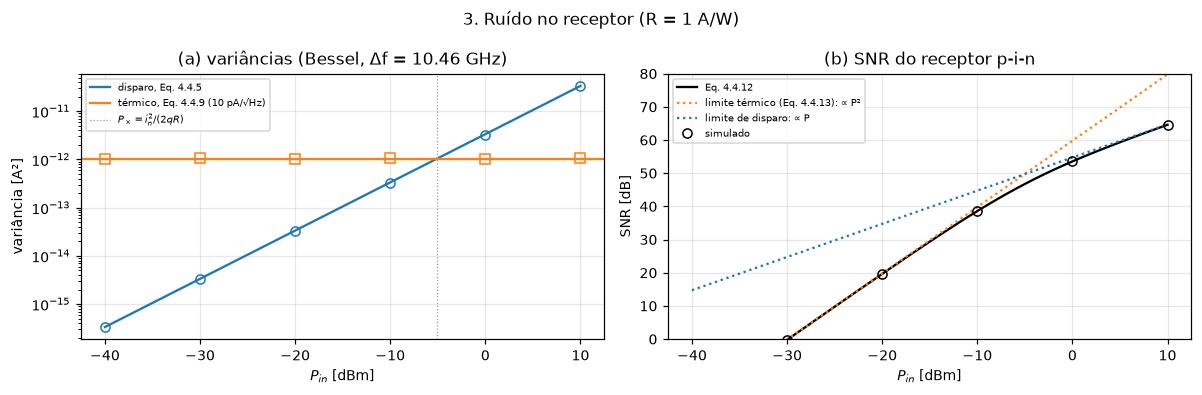

In [4]:
H2 = lowpass_response(f2, B, "bessel", 4)
DF = noise_bandwidth(H2, f2)
IN = 10e-12
p_eixo = np.linspace(-40, 10, 101)
p_pts = np.array([-40, -30, -20, -10, 0, 10])
rng = np.random.default_rng(0)
v_s, v_t = [], []
for p in p_pts:
    I = np.full(N2, R * w(p))
    v_s.append(np.var(apply_response(receiver_noise(I, FS2, rng, thermal=0.0, shot=True), H2)))
    v_t.append(np.var(apply_response(receiver_noise(I, FS2, rng, thermal=IN, shot=False), H2)))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].semilogy(p_eixo, 2 * Q_ELECTRON * R * w(p_eixo) * DF, "-", color=C3[0], label="disparo, Eq. 4.4.5")
ax[0].semilogy(p_pts, v_s, "o", mfc="none", color=C3[0])
ax[0].axhline(IN ** 2 * DF, color=C3[1], label="térmico, Eq. 4.4.9 (10 pA/√Hz)")
ax[0].semilogy(p_pts, v_t, "s", mfc="none", color=C3[1])
Px = IN ** 2 / (2 * Q_ELECTRON * R)
ax[0].axvline(10 * np.log10(Px) + 30, color="0.6", ls=":", lw=0.8, label="$P_\\times = i_n^2/(2qR)$")
ax[0].set(xlabel="$P_{in}$ [dBm]", ylabel="variância [A²]", title=f"(a) variâncias (Bessel, Δf = {DF/1e9:.2f} GHz)")
snr = (R * w(p_eixo)) ** 2 / (2 * Q_ELECTRON * R * w(p_eixo) * DF + IN ** 2 * DF)
ax[1].plot(p_eixo, 10 * np.log10(snr), "k-", label="Eq. 4.4.12")
ax[1].plot(p_eixo, 10 * np.log10((R * w(p_eixo)) ** 2 / (IN ** 2 * DF)), ":", color=C3[1],
           label="limite térmico (Eq. 4.4.13): ∝ P²")
ax[1].plot(p_eixo, 10 * np.log10(R * w(p_eixo) / (2 * Q_ELECTRON * DF)), ":", color=C3[0],
           label="limite de disparo: ∝ P")
snr_med = (R * w(p_pts)) ** 2 / (np.array(v_s) + np.array(v_t))
ax[1].plot(p_pts, 10 * np.log10(snr_med), "o", mfc="none", color="k", label="simulado")
ax[1].set(ylim=(0, 80), xlabel="$P_{in}$ [dBm]", ylabel="SNR [dB]", title="(b) SNR do receptor p-i-n")
for a_ in ax: a_.legend(fontsize=6.5)
fig.suptitle("3. Ruído no receptor (R = 1 A/W)")
fig.tight_layout()
print(f"Δf = {DF/1e9:.3f} GHz | P_× = {10*np.log10(Px)+30:.2f} dBm | disparo medido/Eq. 4.4.5: "
      f"{np.round(np.array(v_s)/(2*Q_ELECTRON*R*w(p_pts)*DF), 4)} | térmico medido/Eq. 4.4.9: "
      f"{np.round(np.array(v_t)/(IN**2*DF), 4)}")
print(f"4k_BT/R_L (300 K, 50 Ω): {thermal_density(300, 50)*1e12:.1f} pA/√Hz")

**Leitura.** (Números na saída da célula.)
- (a) As variâncias simuladas seguem as Eq. 4.4.5 e 4.4.9 (razões entre 0,96 e 1,04 na saída: é a
  flutuação estatística de ~3 % de uma janela de 164 ns filtrada em 10 GHz), com Δf vindo
  da resposta do filtro. O ruído de disparo cresce com a potência; o térmico não depende dela.
  Com 10 pA/√Hz o disparo só passa o térmico acima de $P_\times$ ≈ −5 dBm: em quase todo
  receptor de comunicação o ruído térmico domina, como diz o Agrawal (texto após a Eq. 4.4.12).
- (b) A SNR cresce 20 dB por década de potência no limite térmico e 10 dB por década no de
  disparo; a curva completa passa de uma assíntota à outra em $P_\times$.

## 4. BER de um sinal OOK (back-to-back)

**[Fato: Agrawal, Eq. 4.6.6–4.6.11]** Com ruído gaussiano, correntes médias $I_1$, $I_0$ e
desvios $\sigma_1$, $\sigma_0$ nos bits 1 e 0, o limiar ótimo é
$I_D = (\sigma_0I_1 + \sigma_1I_0)/(\sigma_0 + \sigma_1)$ e

$$\mathrm{BER} = \tfrac{1}{2}\mathrm{erfc}(Q/\sqrt{2}),\qquad Q = \frac{I_1 - I_0}{\sigma_1 + \sigma_0}$$

BER ≈ 1e-9 em Q = 6. É o primeiro teste de ponta a ponta com forma fechada: sinal óptico OOK →
fotodetector com ruído → filtro → amostragem → decisão → contagem de erros.

Montagem: OOK a 10 Gb/s com extinção infinita e bordas suaves (sinal elétrico filtrado com
Bessel de 20 GHz antes de virar potência óptica), receptor com Bessel de ordem 4 em 7,5 GHz,
ruído térmico de 10 pA/√Hz e de disparo, 2e5 bits. Q é medido nas amostras (média e desvio dos
bits 1 e 0), e a BER contada é comparada com ½erfc(Q/√2).

-28.0 dBm: Q = 1.720 | BER contada 4.25e-02 (8506 erros) | ½erfc(Q/√2) = 4.28e-02
-27.0 dBm: Q = 2.155 | BER contada 1.56e-02 (3121 erros) | ½erfc(Q/√2) = 1.56e-02
-26.0 dBm: Q = 2.703 | BER contada 3.65e-03 (731 erros) | ½erfc(Q/√2) = 3.44e-03
-25.0 dBm: Q = 3.405 | BER contada 3.90e-04 (78 erros) | ½erfc(Q/√2) = 3.31e-04
-24.5 dBm: Q = 3.798 | BER contada 8.50e-05 (17 erros) | ½erfc(Q/√2) = 7.28e-05


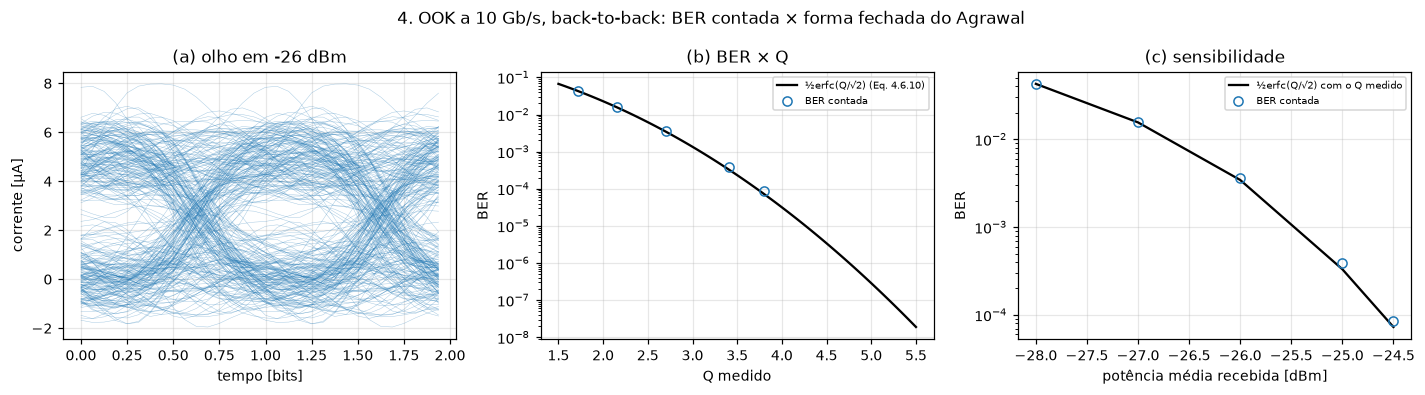

In [5]:
RB, SPS = 10e9, 16
NB = 200_000
FS4 = RB * SPS
bits = np.random.default_rng(1).integers(0, 2, NB)
f4 = np.fft.fftfreq(NB * SPS, 1 / FS4)
x4 = apply_response(np.repeat(bits.astype(float), SPS), lowpass_response(f4, 2 * RB, "bessel", 4))
H4 = lowpass_response(f4, 0.75 * RB, "bessel", 4)

def receptor_ook(p_media_dbm, seed):
    """Q medido, BER contada e ½erfc(Q/√2) para potência média dada (bits equiprováveis)."""
    campo = np.sqrt(2 * w(p_media_dbm) * np.clip(x4, 0, None))[None, :]
    I = photocurrent(campo, R)
    i = apply_response(I + receiver_noise(I, FS4, np.random.default_rng(seed), thermal=IN), H4)
    melhor = None
    for fase in range(SPS):                       # instante de amostragem (atraso do Bessel)
        s = i[fase::SPS]
        I1, I0, s1, s0 = s[bits == 1].mean(), s[bits == 0].mean(), s[bits == 1].std(), s[bits == 0].std()
        Q = (I1 - I0) / (s1 + s0)
        if melhor is None or Q > melhor[0]:
            melhor = (Q, fase, (s0 * I1 + s1 * I0) / (s0 + s1))
    Q, fase, ID = melhor
    ber = np.mean((i[fase::SPS] > ID).astype(int) != bits)
    return Q, ber, 0.5 * erfc(Q / np.sqrt(2)), i, fase

pots = np.array([-28.0, -27.0, -26.0, -25.0, -24.5])
res = [receptor_ook(p, 10 + k) for k, p in enumerate(pots)]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
_, _, _, i_olho, fase_olho = res[2]
for k in range(300):
    ini = (k * SPS + fase_olho - SPS) % (NB * SPS - 3 * SPS)
    ax[0].plot(np.arange(2 * SPS) / SPS, i_olho[ini:ini + 2 * SPS] * 1e6, color=C3[0], lw=0.3, alpha=0.4)
ax[0].set(xlabel="tempo [bits]", ylabel="corrente [µA]", title=f"(a) olho em {pots[2]:.0f} dBm")
q_eixo = np.linspace(1.5, 5.5, 100)
ax[1].semilogy(q_eixo, 0.5 * erfc(q_eixo / np.sqrt(2)), "k-", label="½erfc(Q/√2) (Eq. 4.6.10)")
ax[1].semilogy([r[0] for r in res], [r[1] for r in res], "o", mfc="none", color=C3[0], label="BER contada")
ax[1].set(xlabel="Q medido", ylabel="BER", title="(b) BER × Q")
ax[2].semilogy(pots, [r[2] for r in res], "k-", label="½erfc(Q/√2) com o Q medido")
ax[2].semilogy(pots, [r[1] for r in res], "o", mfc="none", color=C3[0], label="BER contada")
ax[2].set(xlabel="potência média recebida [dBm]", ylabel="BER", title="(c) sensibilidade")
for a_ in ax[1:]: a_.legend(fontsize=6.5)
fig.suptitle("4. OOK a 10 Gb/s, back-to-back: BER contada × forma fechada do Agrawal")
fig.tight_layout()
for p, (Q, ber, ber_q, _, _) in zip(pots, res):
    print(f"{p:.1f} dBm: Q = {Q:.3f} | BER contada {ber:.2e} ({int(round(ber*NB))} erros) | "
          f"½erfc(Q/√2) = {ber_q:.2e}")

**Leitura.** (Números na saída da célula.)
- (a) O olho abre entre o nível 0 (só ruído térmico) e o nível 1 (térmico mais disparo).
- (b)–(c) A BER contada segue $\tfrac{1}{2}\mathrm{erfc}(Q/\sqrt{2})$ dentro do erro de
  contagem: com 2e5 bits, as BER abaixo de ~1e-4 têm poucas dezenas de erros ou menos, e a
  incerteza relativa cresce como $1/\sqrt{\text{erros}}$. A potência para BER = 1e-9 (Q = 6)
  sai por extrapolação da mesma fórmula, sem simular 1e9 bits.
- Este é o modelo do primeiro teste de ponta a ponta do sistema: uma cadeia com resposta
  fechada, que dá um número de BER comparável à teoria.

Testes: issue #20.